# 💼 Forecasting Weekly Product Demand — Part 5: Explaining the Model and Turning Forecasts into Stock Decisions

**Goal of this notebook:**
1. **Explain** what the model relies on (SHAP).
2. **Analyse errors**: where and why the forecast goes wrong.
3. Build a **business layer**: turn the p50/p90 forecasts into safety stock and reorder points, and simulate stock-outs and overstock compared with the baseline.

Everything is done on the **test fold** (10 Oct – 28 Nov 2011), with the same models as Part 4.

## 1. Setup: Rebuild the Test-Fold Forecasts

We load the tuned parameters from the saved bundle and retrain the test-fold models exactly as in Part 4 (training on weeks up to 3 Oct 2011). LightGBM uses a fixed `random_state`, so the forecasts are identical. We check this by recomputing the test WAPE (53.4%).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import lightgbm as lgb

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
PROCESSED_DIR = ROOT / "data" / "processed"

from src.features import (FEATURES, CATEGORICAL, HORIZON, make_features,
                          build_training_set, cap_outliers)
from src.evaluation import evaluate, moving_average_forecast

bundle = joblib.load(ROOT / "models" / "forecast_bundle_v1.pkl")
PARAMS, QUANTILES = bundle["params"], bundle["quantiles"]

weekly = pd.read_parquet(PROCESSED_DIR / "weekly_demand.parquet")
products = pd.read_csv(PROCESSED_DIR / "selected_products.csv",
                       dtype={"StockCode": "string"}).set_index("StockCode")
Y = weekly.pivot(index="week", columns="StockCode", values="units")
weeks = Y.index

E = 95                                   # last training week of the test fold (3 Oct 2011)
train_rows, fence = build_training_set(Y, E)
pred_rows = make_features(cap_outliers(Y.iloc[: E + 1], fence), E)

models, raw = {}, []
for q, a in QUANTILES.items():
    params = PARAMS if a == 0.5 else PARAMS | {"objective": "quantile", "alpha": a}
    m = lgb.LGBMRegressor(**params)
    m.fit(train_rows[FEATURES], train_rows["y"],
          sample_weight=train_rows["scale"], categorical_feature=CATEGORICAL)
    models[q] = m
    pred = m.predict(pred_rows[FEATURES]) * pred_rows["scale"].to_numpy()
    raw.append(np.clip(pred, 0, None).reshape(HORIZON, -1))
fc = dict(zip(QUANTILES, np.sort(np.stack(raw), axis=0)))

actual = Y.iloc[E + 1 : E + 1 + HORIZON].to_numpy()
ma13 = moving_average_forecast(Y, E)
test_weeks = weeks[E + 1 : E + 1 + HORIZON]

print(f"Test weeks: {test_weeks[0]:%d %b %Y} to {test_weeks[-1]:%d %b %Y}")
print(f"Test WAPE (should be 0.534): {evaluate(actual, fc['p50'], Y.iloc[: E + 1])['WAPE']:.3f}")

Test weeks: 10 Oct 2011 to 28 Nov 2011
Test WAPE (should be 0.534): 0.534


## 2. What Does the Model Rely On? (SHAP)

**SHAP** splits each prediction into contributions from each feature: how much did *this* feature push *this* forecast up or down? Averaging the size of these contributions over all 800 test forecasts (100 products × 8 weeks) shows which features matter most.

We explain the **p50 model**. Its output is units ÷ scale (the product's 13-week average), so a SHAP value of +0.10 means "this feature raised the forecast by 10% of the product's recent average".

In [2]:
import shap

X_test = pred_rows[FEATURES]
explainer = shap.TreeExplainer(models["p50"])
sv = explainer(X_test)

# check: base value + contributions = model output
gap = np.abs(sv.values.sum(axis=1) + sv.base_values - models["p50"].predict(X_test)).max()
print(f"SHAP additivity check (should be ~0): {gap:.1e}")

importance = pd.Series(np.abs(sv.values).mean(axis=0), index=FEATURES).sort_values(ascending=False)
importance.round(3).head(10)

SHAP additivity check (should be ~0): 2.7e-15


product          0.082
ly_smooth        0.073
log_scale        0.067
week_of_year     0.045
rmean_4          0.038
weeks_to_xmas    0.034
rmean_8          0.026
ly_same          0.019
n_holidays       0.018
lag_1            0.015
dtype: float64

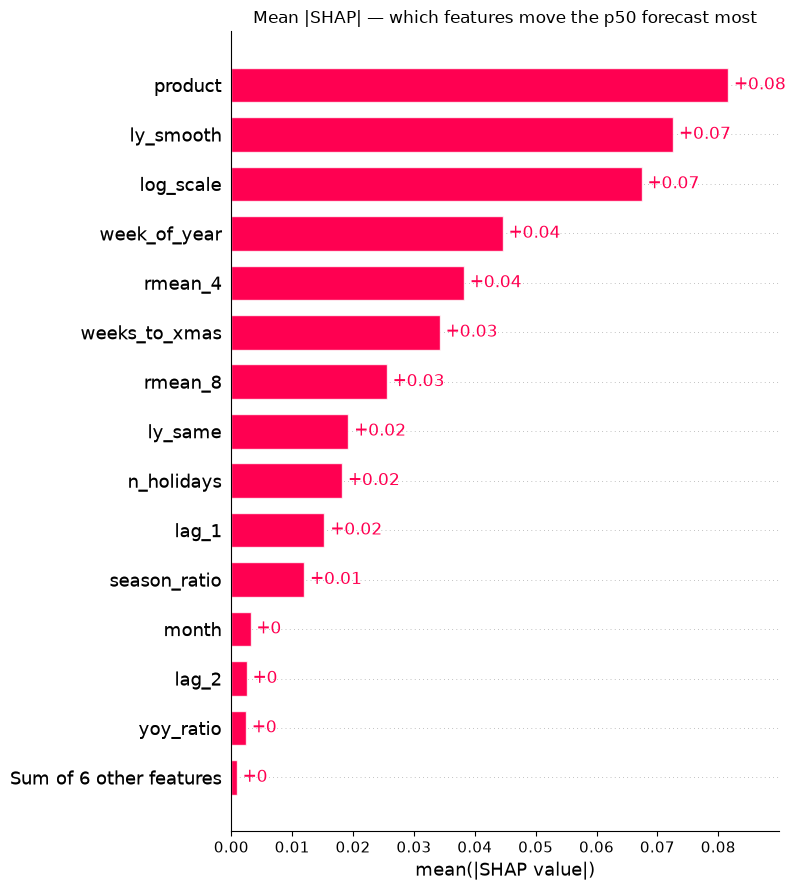

In [3]:
plt.figure()
shap.plots.bar(sv, max_display=15, show=False)
plt.title("Mean |SHAP| — which features move the p50 forecast most")
plt.tight_layout()
plt.show()

📌 **Reading this:**
- **`product`** matters most: each product has its own typical pattern, which the global model learns.
- **`ly_smooth`** (last year's demand around the same week, smoothed) is the main **seasonal signal**, followed by `week_of_year` and `weeks_to_xmas`.
- **`log_scale`** (product size) and the recent averages (`rmean_4`, `rmean_8`, `lag_1`) set the **level**.
- The two ratio features we designed for level changes, **`yoy_ratio` and `season_ratio`, are hardly used**. The model gets that information from `ly_smooth` and the recent averages instead.

### 2.1 — Direction of the effects (beeswarm)

Each dot is one forecast. Colour shows the feature's value (red = high, blue = low), and the position shows whether it pushed the forecast up (right) or down (left). The `product` feature is left out here because it is a category and has no high/low colour.

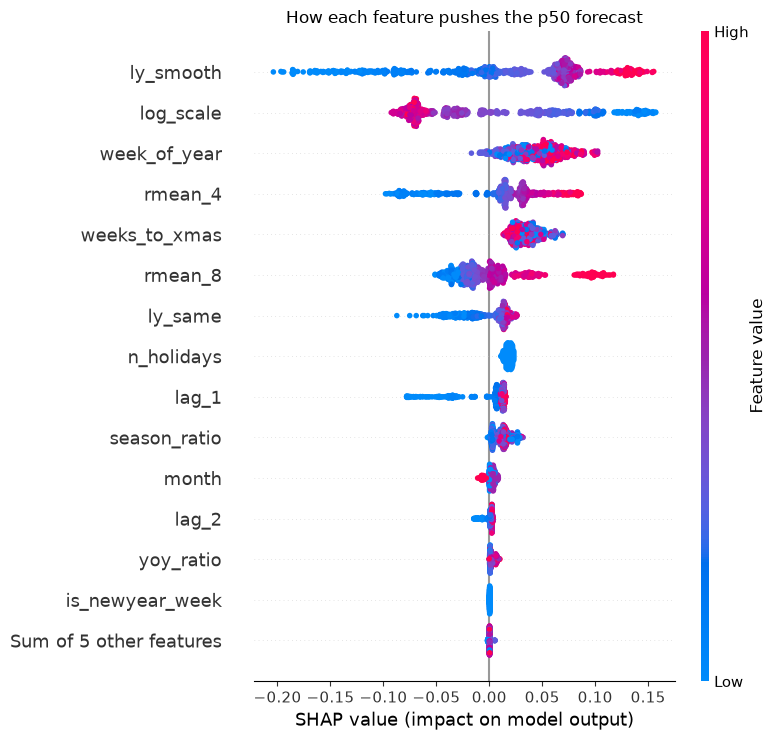

In [4]:
numeric_idx = [i for i, f in enumerate(FEATURES) if f != "product"]

plt.figure()
shap.plots.beeswarm(sv[:, numeric_idx], max_display=15, show=False)
plt.title("How each feature pushes the p50 forecast")
plt.tight_layout()
plt.show()

📌 **Reading this:**
- **`ly_smooth`**: high last-year demand (red) pushes the forecast up and low (blue) pushes it down. That is the expected seasonal effect.
- **`log_scale`**: for the **largest products (red), the forecast is pushed below their recent average**. This is one source of the under-forecasting bias: the model is cautious about big sellers staying at their current level.
- **`week_of_year` and `weeks_to_xmas`** push almost every test forecast **up**, so the model does recognise the October–November gift season.
- **`rmean_4`, `lag_1`**: strong recent weeks push the forecast up and weak ones push it down (short-term momentum).
- **Why the peak was missed:** the seasonal features move the forecast by only about **5–10% of the product's recent level**, while actual November demand was about 30% above the recent 13-week level. The model learned the *direction* of the season but **underestimates its size**. With only one previous peak to learn from, it can't be more confident.

## 3. Error Analysis: Where Does the Forecast Go Wrong?

Four questions about the p50 forecast on the test fold:
1. Is the error spread evenly, or do a few products cause most of it?
2. Does accuracy depend on the demand pattern (smooth / erratic / lumpy from Part 2)?
3. How much of the error comes from one-off bulk-order weeks?
4. Does the under-forecasting grow as the gift season peaks?

In [5]:
from src.features import outlier_fence

abs_err = np.abs(fc["p50"] - actual)

prod = pd.DataFrame({
    "actual": actual.sum(axis=0),
    "forecast": fc["p50"].sum(axis=0),
    "abs_err": abs_err.sum(axis=0),
}, index=Y.columns)
prod["WAPE"] = prod["abs_err"] / prod["actual"]
prod["Bias"] = (prod["forecast"] - prod["actual"]) / prod["actual"]
prod["share_of_error"] = prod["abs_err"] / prod["abs_err"].sum()
prod = prod.join(products[["Description", "pattern"]])

# 1. concentration
print(f"Top 10 products cause {prod['share_of_error'].nlargest(10).sum():.1%} of all absolute error "
      f"(they are {prod['actual'].loc[prod['share_of_error'].nlargest(10).index].sum() / prod['actual'].sum():.1%} of test demand)\n")

# 2. by demand pattern
by_pattern = prod.groupby("pattern").apply(lambda g: pd.Series({
    "products": len(g),
    "WAPE": g["abs_err"].sum() / g["actual"].sum(),
    "Bias": (g["forecast"].sum() - g["actual"].sum()) / g["actual"].sum(),
}))
print("By demand pattern:")
print(by_pattern.round(3), "\n")

# 3. bulk-order weeks (fence from training weeks only)
bulk = actual > outlier_fence(Y.iloc[: E + 1]).to_numpy()
print(f"Bulk-order product-weeks: {bulk.sum()} of {bulk.size} "
      f"({bulk.mean():.1%}), causing {abs_err[bulk].sum() / abs_err.sum():.1%} of all absolute error")

Top 10 products cause 38.3% of all absolute error (they are 33.0% of test demand)

By demand pattern:
         products   WAPE   Bias
pattern                        
erratic      66.0  0.575 -0.205
lumpy         3.0  0.841 -0.718
smooth       31.0  0.395 -0.035 

Bulk-order product-weeks: 31 of 800 (3.9%), causing 28.5% of all absolute error


📌 **Reading this:**
- **Error is spread across many products:** the 10 worst products cause 38.3% of the error while making up 33.0% of demand, only slightly more than their share.
- **Smooth products are forecast well** (WAPE 39.5%, bias only −3.5%). Erratic products are much harder (57.5%, bias −20.5%), and the 3 lumpy products are the worst (84.1%, bias −71.8%). Most of the under-forecasting comes from erratic and lumpy demand.
- **One-off bulk orders matter a lot:** only 31 of 800 product-weeks (3.9%) were above the training fence, but they cause **28.5%** of all absolute error. No demand model can predict these orders; in practice they are handled through advance orders.

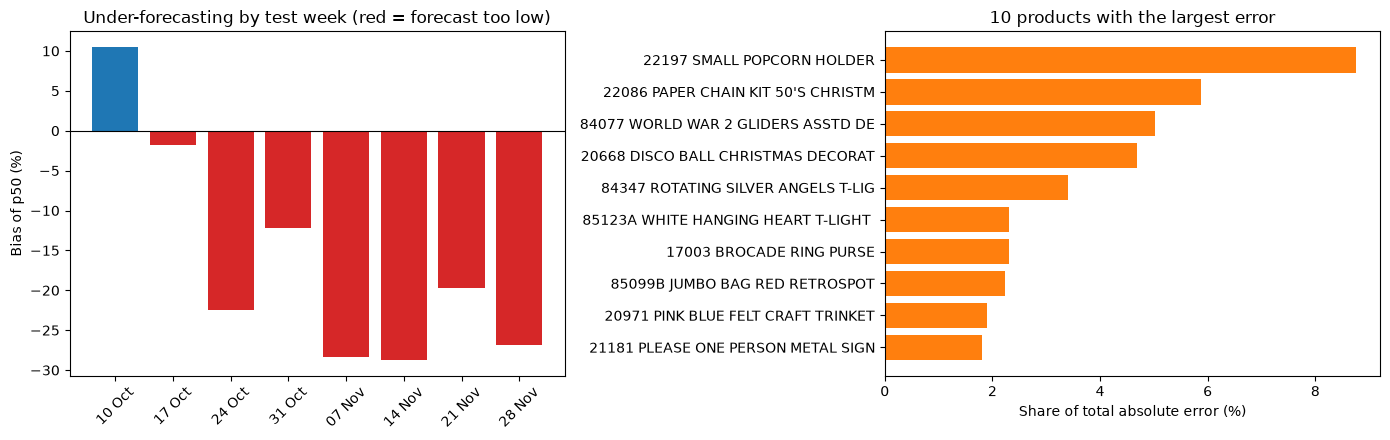

,actual,p50,p90,bias_p50
week,,,,
2011-10-10,21968,24272.588,57834.871,0.105
2011-10-17,24220,23774.994,53946.707,-0.018
2011-10-24,30259,23449.373,53595.007,-0.225
2011-10-31,27346,24008.352,54628.808,-0.122
2011-11-07,35289,25273.605,56506.740,-0.284
2011-11-14,36000,25649.049,56890.848,-0.288
2011-11-21,31367,25180.631,55570.661,-0.197
2011-11-28,33427,24454.016,54043.821,-0.268


In [6]:
# 4. bias by week
by_week = pd.DataFrame({"actual": actual.sum(axis=1), "p50": fc["p50"].sum(axis=1),
                        "p90": fc["p90"].sum(axis=1)}, index=test_weeks)
by_week["bias_p50"] = (by_week["p50"] - by_week["actual"]) / by_week["actual"]

worst = prod.nlargest(10, "abs_err")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
colors = np.where(by_week["bias_p50"] < 0, "tab:red", "tab:blue")
axes[0].bar(by_week.index.strftime("%d %b"), by_week["bias_p50"] * 100, color=colors)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_ylabel("Bias of p50 (%)")
axes[0].set_title("Under-forecasting by test week (red = forecast too low)")
axes[0].tick_params(axis="x", rotation=45)

labels = [f"{c} {d[:28]}" for c, d in zip(worst.index, worst["Description"])]
axes[1].barh(labels, worst["share_of_error"] * 100, color="tab:orange")
axes[1].invert_yaxis()
axes[1].set_xlabel("Share of total absolute error (%)")
axes[1].set_title("10 products with the largest error")
plt.tight_layout()
plt.show()

by_week.round(3)

In [7]:
# the 10 worst products in detail
worst[["Description", "pattern", "actual", "forecast", "WAPE", "Bias", "share_of_error"]].round(3)

,Description,pattern,actual,forecast,WAPE,Bias,share_of_error
StockCode,,,,,,,
22197,SMALL POPCORN HOLDER,erratic,19042,7821.962,0.590,-0.589,0.088
22086,PAPER CHAIN KIT 50'S CHRISTMAS,erratic,10763,3238.287,0.699,-0.699,0.059
84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,erratic,11948,5533.063,0.538,-0.537,0.050
20668,DISCO BALL CHRISTMAS DECORATION,lumpy,7233,1218.105,0.832,-0.832,0.047
84347,ROTATING SILVER ANGELS T-LIGHT HLDR,lumpy,5246,884.434,0.831,-0.831,0.034
85123A,WHITE HANGING HEART T-LIGHT HOLDER,smooth,6622,4497.893,0.448,-0.321,0.023
17003,BROCADE RING PURSE,erratic,3088,3191.513,0.955,0.034,0.023
85099B,JUMBO BAG RED RETROSPOT,smooth,9249,9480.242,0.310,0.025,0.022
20971,PINK BLUE FELT CRAFT TRINKET BOX,erratic,3423,1465.251,0.713,-0.572,0.019


📌 **Reading this:**
- **The under-forecasting grows with the peak:** the first test week is over-forecast by 10.5%, but from late October the forecast is **12–29% too low** (20–29% in most weeks), as actual demand climbs from about 22,000 to 36,000 units while the p50 stays around 23,400–25,600.
- **Three of the five worst products are Christmas items** (*Paper Chain Kit 50's Christmas*, *Disco Ball Christmas Decoration*, *Rotating Silver Angels T-Light Holder*) and best-sellers with strong autumn ramps (*Small Popcorn Holder*). Their demand jumps sharply in November, and the model underestimates the jump.
- **Note:** the sum of the 100 product-level p90 forecasts (about 54,000–58,000 a week) is far above actual total demand. Product-level p90s are correct individually (82% coverage), but they **must not be added up**: not every product has a bad week at the same time. A p90 for the total would need its own model.

## 4. Business Layer: From Forecast to Stock Decision

**Safety stock and reorder point.** The p50 is the "most likely" demand. The p90 is a level that demand exceeds in only about 10% of weeks. So:
- **Safety stock = p90 − p50**: extra stock held to protect against uncertainty
- **Stock target (order-up-to level) = p90 = p50 + safety stock**: aims for about a **90% service level** (no stock-out in 9 of 10 weeks)
- With a supplier lead time of L weeks, the **reorder point** is the forecast demand over those L weeks plus the safety stock.

**Simulation on the test fold.** For each product and week, the shop starts the week with a stock target. If demand is higher, the difference is **lost sales**; if lower, the difference is **leftover stock**. We compare four policies:
1. 13-week moving average, no safety stock
2. **Moving average + 1.28 × standard deviation** of the last 13 weeks: the classic textbook safety stock for 90% service, assuming normally distributed demand
3. LightGBM p50
4. **LightGBM p90**

**Measures:**
- **Service level**: share of product-weeks with no stock-out
- **Fill rate**: share of demand actually served
- **Stock ÷ demand**: total stock held relative to total demand (lower = less money tied up)

**Simplification:** every week is stocked up to the target and stock arrives instantly (no lead time, no carry-over). This isolates the effect of the forecast itself.

In [8]:
recent = Y.iloc[E - 12 : E + 1]                  # last 13 training weeks
level, sigma = recent.mean().to_numpy(), recent.std().to_numpy()

def simulate(stock):
    """stock and actual: arrays (weeks x products)."""
    sold = np.minimum(actual, stock)
    short = actual - sold
    return {
        "service level": (short == 0).mean(),
        "fill rate": sold.sum() / actual.sum(),
        "stock / demand": stock.sum() / actual.sum(),
        "lost sales (units)": short.sum(),
        "leftover (units)": (stock - sold).sum(),
    }

policies = {
    "MA13, no safety stock": np.tile(level, (HORIZON, 1)),
    "MA13 + 1.28σ (classic 90%)": np.tile(level + 1.28 * sigma, (HORIZON, 1)),
    "LightGBM p50": fc["p50"],
    "LightGBM p90": fc["p90"],
}
sim = pd.DataFrame({name: simulate(s) for name, s in policies.items()}).T
sim.round(3)

,service level,fill rate,stock / demand,lost sales (units),leftover (units)
"MA13, no safety stock",0.572,0.639,0.857,86655.462,52331.462
MA13 + 1.28σ (classic 90%),0.835,0.832,1.651,40230.875,196333.535
LightGBM p50,0.559,0.642,0.817,85978.193,42164.800
LightGBM p90,0.904,0.891,1.847,26226.648,229368.110


📌 **Reading this:**
- **Without safety stock** (moving average or LightGBM p50), only about **56–57%** of product-weeks avoid a stock-out. Planning stock from a "most likely" forecast runs out of stock almost every other week.
- **The classic textbook policy (MA13 + 1.28σ) misses its own target:** it aims for 90% service but reaches only **83.5%**, because it assumes normally distributed demand, while real weekly sales have sudden spikes.
- **LightGBM p90 hits its target:** **90.4%** service and 89.1% fill rate, with **35% fewer lost sales** than the classic policy (26,227 vs 40,231 units). That is the payoff of the well-calibrated quantile forecasts.

### 4.1 — Service level vs stock held

The grey curve shows the classic policy for every safety factor z from 0 to 3: more safety stock buys a higher service level. LightGBM p50 and p90 are single points. **A policy is better if it reaches the same service level with less stock**, i.e. it sits above and to the left of the grey curve.

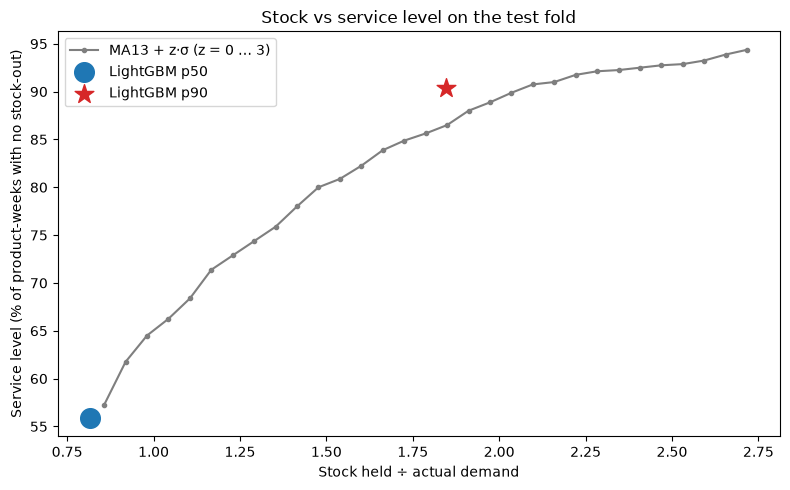

LightGBM p90 service level: 90.4% with stock = 1.85 x demand
Classic policy at the same service level needs stock = 2.07 x demand
Classic policy needs 12.1% more stock; LightGBM p90 needs 10.8% less


In [9]:
zs = np.arange(0, 3.01, 0.1)
curve = pd.DataFrame([simulate(np.tile(level + z * sigma, (HORIZON, 1))) | {"z": z} for z in zs])

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(curve["stock / demand"], curve["service level"] * 100, color="tab:grey", marker=".",
        label="MA13 + z·σ (z = 0 … 3)")
for name, marker, color in [("LightGBM p50", "o", "tab:blue"), ("LightGBM p90", "*", "tab:red")]:
    r = sim.loc[name]
    ax.scatter(r["stock / demand"], r["service level"] * 100, s=200, marker=marker,
               color=color, zorder=3, label=name)
ax.set_xlabel("Stock held ÷ actual demand")
ax.set_ylabel("Service level (% of product-weeks with no stock-out)")
ax.set_title("Stock vs service level on the test fold")
ax.legend()
plt.tight_layout()
plt.show()

# stock the classic policy needs to match LightGBM p90's service level
p90_service = sim.loc["LightGBM p90", "service level"]
classic_stock = np.interp(p90_service, curve["service level"], curve["stock / demand"])
p90_stock = sim.loc["LightGBM p90", "stock / demand"]
print(f"LightGBM p90 service level: {p90_service:.1%} with stock = {p90_stock:.2f} x demand")
print(f"Classic policy at the same service level needs stock = {classic_stock:.2f} x demand")
print(f"Classic policy needs {classic_stock / p90_stock - 1:.1%} more stock; "
      f"LightGBM p90 needs {1 - p90_stock / classic_stock:.1%} less")

📌 **Reading this:**
- The LightGBM p90 point (red star) sits **above and to the left** of the classic policy's curve: for the same stock it gives a higher service level, and for the same service level it needs less stock.
- To reach LightGBM p90's 90.4% service level, the classic policy would need stock of **2.07× demand** instead of **1.85×**, about **12% more stock** (put the other way, LightGBM p90 needs about 11% less), which is money tied up in inventory.
- **Caveat:** the simulation restocks to target every week and does not carry leftover stock forward, so the absolute stock levels are higher than in a real shop. The **comparison** between policies is what matters, not the absolute numbers.

### 4.2 — What the shop would see: next 8 weeks for one product

Using the final model from Part 4 (trained on all data), this is the stock plan for the top product. **Safety stock = p90 − p50**, and the **stock target = p90**, aiming for about 90% service.

In [10]:
from src.forecast import forecast

plan = forecast(bundle)
plan["safety_stock"] = (plan["p90"] - plan["p50"]).round(1)
plan["stock_target"] = plan["p90"]

top = products.index[0]
print(f"{top} – {bundle['product_names'][top]}")
plan[plan["StockCode"] == str(top)][["week", "h", "p50", "safety_stock", "stock_target"]]

84077 – WORLD WAR 2 GLIDERS ASSTD DESIGNS


,week,h,p50,safety_stock,stock_target
78,2011-12-05,1,665.0,1108.7,1773.7
178,2011-12-12,2,650.3,1155.1,1805.4
278,2011-12-19,3,451.1,990.2,1441.3
378,2011-12-26,4,132.4,195.2,327.6
478,2012-01-02,5,450.0,649.3,1099.3
578,2012-01-09,6,458.8,816.9,1275.7
678,2012-01-16,7,513.5,823.5,1337.0
778,2012-01-23,8,514.6,857.0,1371.6


📌 **Reading this:** For the top product, the most likely weekly demand (p50) is about 450–665 units, but the stock target (p90) is about 1,100–1,800, so the safety stock is larger than the expected demand itself. That reflects how volatile this product's weekly sales are: covering 9 out of 10 weeks needs a large buffer. In the New Year week (26 Dec) the target drops to about 330 units, because the shop is closed or nearly closed. The API and the UI return the same kind of table; the live app now uses the improved Part 7 model, so its numbers differ slightly.

## 5. Summary

**What the model relies on (SHAP)**
- Product identity, last year's smoothed demand (`ly_smooth`), product size and recent averages drive the forecast. `week_of_year` and `weeks_to_xmas` push forecasts up in the gift season.
- The seasonal features raise forecasts by only about 5–10%, while actual November demand was about 30% above the recent level, which explains the missed peak.

**Where it goes wrong**
- Smooth products are forecast well (WAPE 39.5%, bias −3.5%); erratic and lumpy products are much harder.
- One-off bulk orders are 3.9% of product-weeks but cause **28.5%** of the error.
- Under-forecasting grows to 20–29% in November, worst for Christmas items.

**Business value (test fold, 8 weeks × 100 products)**

| Policy | Service level | Fill rate | Stock ÷ demand | Lost sales (units) |
|---|---|---|---|---|
| Moving average, no safety stock | 57.2% | 63.9% | 0.86 | 86,655 |
| Moving average + 1.28σ (classic 90%) | 83.5% | 83.2% | 1.65 | 40,231 |
| **LightGBM p90** | **90.4%** | **89.1%** | 1.85 | **26,227** |

- LightGBM p90 **meets its 90% service target**, while the classic policy falls short (83.5%).
- At the same 90.4% service level, LightGBM p90 needs about **11% less stock** than the classic policy.
- Lost sales fall by **35%** compared with the classic policy.

**Recommendations**
- Plan stock from **p90 (safety stock = p90 − p50)**, not from the median forecast.
- Handle large B2B orders through an advance-order process; they can't be forecast.
- Watch Christmas items closely in October–November, where the model under-forecasts.

**Future work:** a "Christmas item" feature, more years of history, special methods (Croston/TSB) for lumpy products, and a simulation with lead times and stock carry-over.

**Next:** the FastAPI service (`app/`), tests, a small chart UI and deployment on Render. Part 6 then adds a SQL layer.

> **Update (Part 7):** a gift-season feature (the "Christmas item" idea above) and order-count features were tested in Part 7.